In [ ]:
import h5py, json, numpy as np, torch
import matplotlib.pyplot as plt
from pathlib import Path

from ddpm.diffusion.rad_inpainting_scaled import inpaint_scaled

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data_dir = Path("/datasets/training/earthquake/SISSLE_100Hz/south30/20231120")
files = ["south30_100Hz_UTC_20231120_040101.788.h5",
         "south30_100Hz_UTC_20231120_040201.788.h5",
         "south30_100Hz_UTC_20231120_040301.788.h5"]
fs = 100   # Hz

In [2]:
def show_h5(path):
    with h5py.File(path, "r") as f:
        f.visititems(lambda name, obj: print(name, obj.shape if isinstance(obj, h5py.Dataset) else "", dict(obj.attrs) if len(obj.attrs) else ""))
show_h5(data_dir/files[0])

DAS (6000, 7488) {'Acoustic Output': b'Differential', 'Attenuator 1': b'0.0', 'Attenuator 2': b'2.3', 'CPUTimeStamp': b'2023-11-15T21:30:00.644842', 'Continuous Mode': b'', 'Decimation Filter': b'', 'Defragmented': b'', 'Diagnostic Output': b'R, S, As & dP', 'Diff Amplify Factor': b'', 'Fibre Length Multiplier': b'1.0209523838714072', 'Fibre Length per Metre': b'1.0', 'Fibre Type': b'Standard', 'FibreIndex': b'1.4682', 'FileInfo': b'', 'GPSTimeStamp': b'2023-11-15T21:30:01.788320', 'GaugeLength': b'10.0', 'ISO8601 Timestamp': b'2023-11-15T21:30:01.788+00:00', 'Integration Cut Off (Hz)': b'3.14', 'MeasureLength[m]': b'', 'Norm Offset': b'-7500', 'Normalization': b'', 'OffsetLength': b'64.0', 'Optical Delay': b'', 'OutputDecimation[bool]': b'', 'P': b'', 'P Coefficients': b'1.000000;1.000000;1.000000;1.000000;1.000000\r\n', 'Peak Voltage 2 (V)': b'0.0', 'PeakVoltage[V]': b'2.0', 'Power Decrement': b'0.0', 'PreTrigSamples': b'', 'Precise Sampling Frequency (Hz)': b'2000.0', 'Pulse 2 Delay

In [ ]:
key = "DAS"
parts = []
for fn in files:
    with h5py.File(data_dir/fn, "r") as f:
        parts.append(f[key][()].astype(np.float32).T)  # (time, channels) to (channels, time)
raw = np.concatenate(parts, axis=1)
print("merged:", raw.shape, f"= {raw.shape[1]/fs:.0f} s")   # (7488, 18000)

merged: (7488, 18000) = 180 s


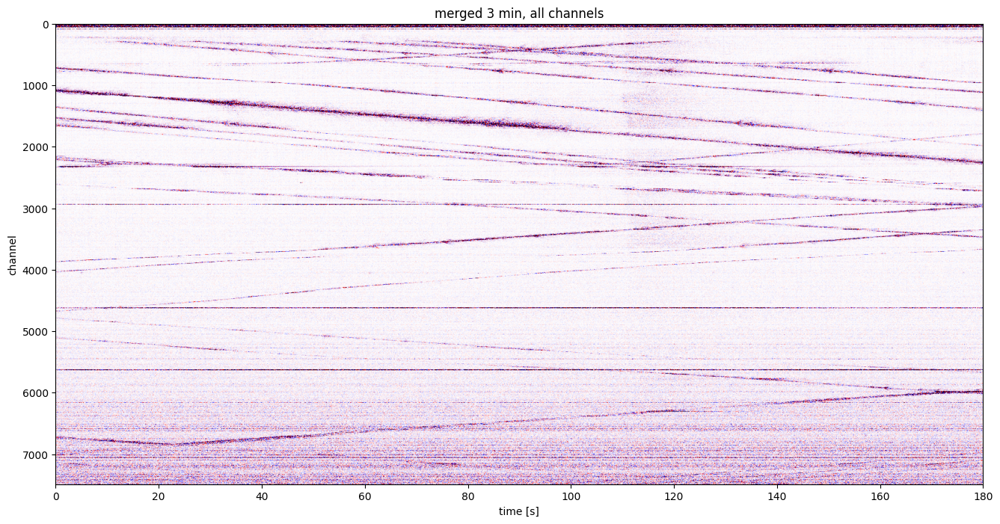

In [4]:
step_c, step_t = 8, 10
ov = raw[::step_c, ::step_t]
v = np.percentile(np.abs(ov), 99)
plt.figure(figsize=(16,8))
plt.imshow(ov, aspect="auto", cmap="seismic", vmin=-v, vmax=v,
           extent=[0, raw.shape[1]/fs, raw.shape[0], 0])
plt.xlabel("time [s]"); plt.ylabel("channel"); plt.title("merged 3 min, all channels")
plt.show()

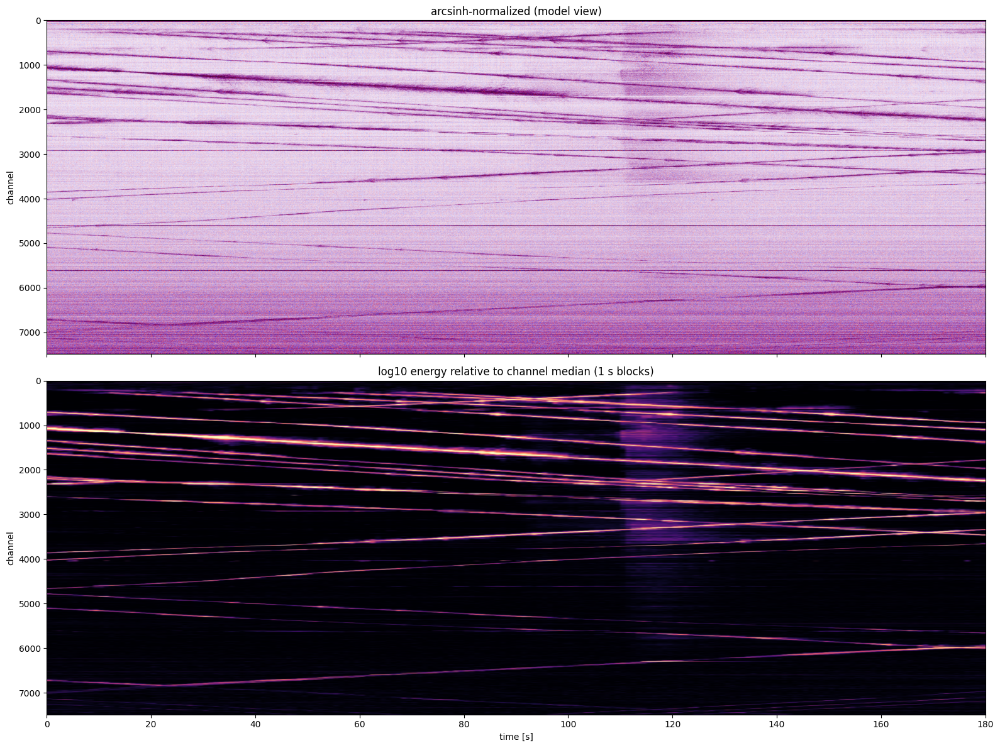

In [5]:
s, A_max = 50.0, 12350.0
norm = lambda a: np.arcsinh(a/s) / np.arcsinh(A_max/s)

fig, ax = plt.subplots(2,1, figsize=(16,12), sharex=True)


ax[0].imshow(norm(raw[::4, ::2]), aspect="auto", cmap="seismic", vmin=-1, vmax=1,
             extent=[0, raw.shape[1]/fs, raw.shape[0], 0])
ax[0].set_title("arcsinh-normalized (model view)")

# energy per channel and second, each channel divided by its median so weak signals become visible
blk = fs                                                     
rms = np.sqrt((raw[:, :raw.shape[1]//blk*blk]**2).reshape(raw.shape[0], -1, blk).mean(-1))
rms = rms / np.median(rms, axis=1, keepdims=True)
ax[1].imshow(np.log10(rms), aspect="auto", cmap="magma", vmin=0, vmax=1.5,
             extent=[0, raw.shape[1]/fs, raw.shape[0], 0])
ax[1].set_title("log10 energy relative to channel median (1 s blocks)")
ax[1].set_xlabel("time [s]")
for a in ax: a.set_ylabel("channel")
plt.tight_layout(); plt.show()

In [ ]:
t_start_s = 100.0
W_samp    = 3072     # 30.72 s = 6 x 512
c0, c1    = 0, 29*256      # 7424 channels = 29 x 256

seg = raw[c0:c1, int(t_start_s*fs): int(t_start_s*fs)+W_samp]
s, A_max = 50.0, 12350.0
seg_n = np.arcsinh(seg/s) / np.arcsinh(A_max/s)
x_full = torch.from_numpy(seg_n).float()[None,None]        
H, W = x_full.shape[-2:]
print("x_full:", (H,W), f"| std {x_full.std():.3f} (train 0.247) | max {x_full.abs().max():.3f}")

x_full: (7424, 3072) | std 0.252 (train 0.247) | max 1.110


In [7]:
import json, time
import torch.nn.functional as F
from ddpm.diffusion.rad_noise_scheduler import RADNoiseScheduler
from ddpm.models.unet_rad import RAD
from ddpm.diffusion.rad_inpainting_scaled import inpaint_scaled

checkpoints=Path("checkpoints")
scheduler_rad=RADNoiseScheduler(ph1_steps=1000,ph2_steps=1000,beta_start=1e-4,beta_end=0.02,device=device)

with open(checkpoints/"data_scaling.json") as f: scaling=json.load(f)
data_scale=scaling["data_scale"]
print("data_scale:",data_scale)

def load_model(path,key):
    m=RAD(in_channels=1,out_channels=1,base_channels=64,channels_multiplier=(1,1,2,2,4),nbr_rb=2,dropout=0.1).to(device)
    m.load_state_dict(torch.load(path,map_location=device)[key])
    m.eval()
    return m

model_v2=load_model(checkpoints/"das_rad_earthquake_model_v2.pth","ema_model_rad")  # v2: EMA
model_v3=load_model(checkpoints/"das_rad_earthquake_model_v3.pth","ema_model_rad")  # v3:EMA + scaling

models=[("v2 EMA",model_v2,1.0),("v3 EMA (scaled)",model_v3,data_scale)]
print("models loaded")

data_scale: 2.023162409488313


models loaded


In [ ]:
blk=25         # 0.25 s blocks
k_thr=3.0      # how much louder than the neighbor channels
nb=129         # neighbor window across channels (+-64)
hw=12          # mask half-width in channels
min_len_s=3    # keep only structures lasting >= 3 s

# energy per (channel, block), relative to the channel median -> persistent channels drop out
T_blk=W//blk
E=torch.from_numpy(seg[:,:T_blk*blk]).float().to(device)
E=E.pow(2).reshape(H,T_blk,blk).mean(-1).sqrt()
E=E/E.median(dim=1,keepdim=True).values
E=E[None,None]                                                      

# typical level of the neighbor channels at the same time (median over +-64 channels)
Ep=F.pad(E,(0,0,nb//2,nb//2),mode="reflect")
bg=Ep.unfold(2,nb,1).median(dim=-1).values                         
det=(E/bg>k_thr).float()

# persistence: lines shift about 1-2 channels per block -> tolerate +-8 channels, require >= L blocks in a row 
L=int(min_len_s*fs/blk)
d=F.max_pool2d(det,(17,1),1,(8,0))
run=F.avg_pool2d(d,(1,L),1,(0,L//2),count_include_pad=False)[...,:T_blk]
long=F.max_pool2d((run>=0.9).float(),(1,L+1),1,(0,L//2))[...,:T_blk]   # extend back to the segment ends
keep=det*long

# widen across channels (and slightly along time), back to sample resolution
keep=F.max_pool2d(keep,(2*hw+1,3),1,(hw,1))
keep=keep.repeat_interleave(blk,dim=-1)
keep=F.pad(keep,(0,W-keep.shape[-1],0,0),mode="replicate")     # rest of the samples (3072 not divisible by 25)

M_full=(1.0-keep).cpu()                                             
e=E[0,0].cpu().numpy()
print(f"masked share: {(M_full==0).float().mean()*100:.1f} %")

masked share: 10.5 %


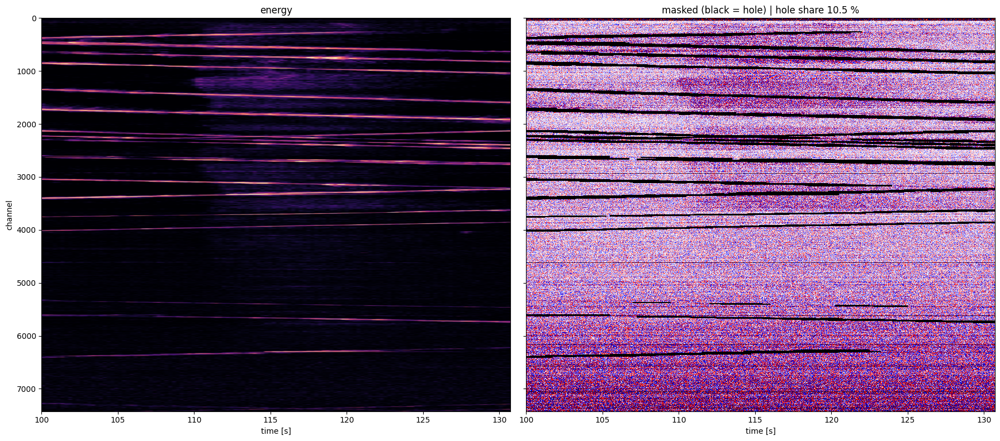

In [ ]:
ext=[t_start_s,t_start_s+W/fs,c1,c0]    # plot extent (time [s], channel)
cmap=plt.get_cmap("seismic").copy(); cmap.set_bad("black")
w_full=float(torch.quantile(x_full[0,0,::4,::2].abs().flatten(),0.98))

masked=x_full[0,0].clone(); masked[M_full[0,0]==0]=float("nan")
fig,ax=plt.subplots(1,2,figsize=(18,8),sharey=True)
ax[0].imshow(np.log10(e),aspect="auto",cmap="magma",vmin=0,vmax=1.5,extent=ext); ax[0].set_title("energy")
ax[1].imshow(masked[::4,::2],aspect="auto",cmap=cmap,vmin=-w_full,vmax=w_full,interpolation="nearest",extent=ext)
ax[1].set_title(f"masked (black = hole) | hole share {(M_full==0).float().mean()*100:.1f} %")
for a in ax: a.set_xlabel("time [s]")
ax[0].set_ylabel("channel"); plt.tight_layout(); plt.show()

In [ ]:
def inpaint_tiled_full(model,scale,x,m,ph=256,pw=512,batch_size=8,seed=0,max_tiles=None):
    out=x.clone()
    todo=[(i,j) for i in range(0,x.shape[-2],ph) for j in range(0,x.shape[-1],pw)
          if (m[...,i:i+ph,j:j+pw]==0).any()]
    if max_tiles: todo=todo[:max_tiles]    # for the time test only
    print(f"{len(todo)} tiles with a hole")
    gen=torch.Generator(device=device).manual_seed(seed)
    for b in range(0,len(todo),batch_size):
        idx=todo[b:b+batch_size]
        xb=torch.cat([x[...,i:i+ph,j:j+pw] for i,j in idx]).to(device)
        mb=torch.cat([m[...,i:i+ph,j:j+pw] for i,j in idx]).to(device)
        r,_,_=inpaint_scaled(model,scheduler_rad,xb,mb,device,scale=scale,generator=gen)
        for k,(i,j) in enumerate(idx):
            out[...,i:i+ph,j:j+pw]=r[k:k+1].cpu()
    return out

In [10]:
t0=time.time()
_=inpaint_tiled_full(model_v2,1.0,x_full,M_full,max_tiles=8)
dt=time.time()-t0
n_tiles=sum((M_full[...,i:i+256,j:j+512]==0).any().item()
            for i in range(0,H,256) for j in range(0,W,512))
print(f"8 tiles: {dt:.0f} s -> all {n_tiles} tiles ≈ {dt/8*n_tiles/60:.0f} min per model")

8 tiles with a hole
8 tiles: 75 s -> all 99 tiles ≈ 16 min per model


In [11]:
res_full={}
for name,model,scale in models:
    res_full[name]=inpaint_tiled_full(model,scale,x_full,M_full)
    print(name,"done")

99 tiles with a hole
v2 EMA done
99 tiles with a hole
v3 EMA (scaled) done


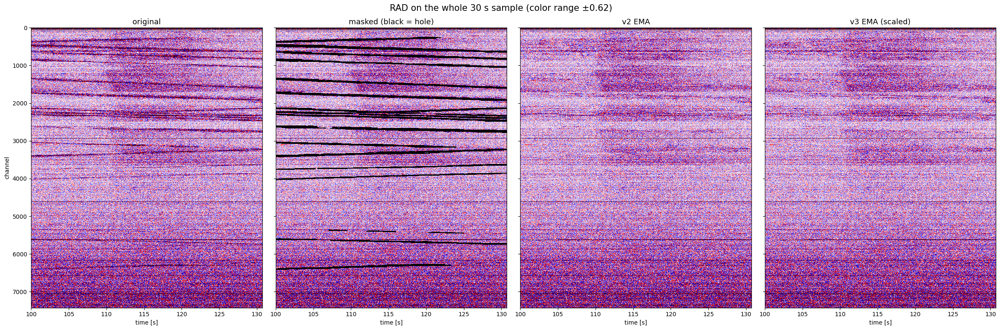

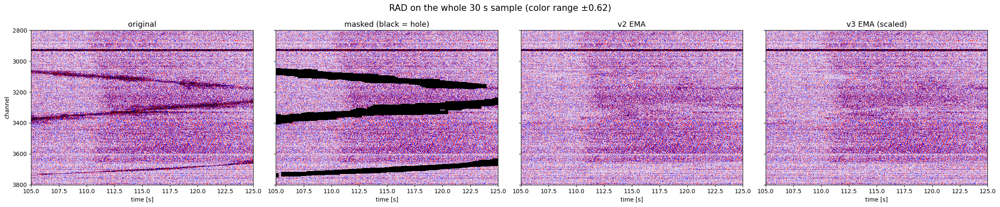

In [ ]:
def show_full(zoom=None,step=(4,2)):
    """zoom = (ch0, ch1, t0 [s], t1 [s]) shows only a section at full resolution."""
    panels=[(x_full[0,0],"original"),(masked,"masked (black = hole)")]+[(r[0,0],n) for n,r in res_full.items()]
    if zoom:
        zc0,zc1=zoom[0]-c0,zoom[1]-c0
        zt0,zt1=int((zoom[2]-t_start_s)*fs),int((zoom[3]-t_start_s)*fs)
        sl=(slice(zc0,zc1),slice(zt0,zt1)); ex=[zoom[2],zoom[3],zoom[1],zoom[0]]; st=(1,1)
    else:
        sl=(slice(None),slice(None)); ex=ext; st=step
    fig,axes=plt.subplots(1,len(panels),figsize=(6*len(panels),8 if not zoom else 5),sharey=True)
    for a,(img,title) in zip(axes,panels):
        a.imshow(img[sl][::st[0],::st[1]],aspect="auto",cmap=cmap,vmin=-w_full,vmax=w_full,
                 interpolation="nearest",extent=ex)
        a.set_title(title,fontsize=13); a.set_xlabel("time [s]")
    axes[0].set_ylabel("channel")
    fig.suptitle(f"RAD on the whole 30 s sample (color range ±{w_full:.2f})",fontsize=15)
    plt.tight_layout(); plt.show()

show_full()
show_full(zoom=(2800,3800,105,125))  # earthquake + traffic

In [ ]:
hole=(M_full==0)
ring=(F.max_pool2d(1-M_full,33,1,16)>0)&~hole  # 16 channels/samples around the holes
for name,r in res_full.items():
    rms_h=r[hole].pow(2).mean().sqrt(); rms_r=r[ring].pow(2).mean().sqrt()
    print(f"{name:18s} | RMS hole/ring {rms_h/rms_r:.2f}   (~1 = as loud as the surroundings, <1 = pale)")

v2 EMA             | RMS hole/ring 0.86   (~1 = as loud as the surroundings, <1 = pale)
v3 EMA (scaled)    | RMS hole/ring 0.90   (~1 = as loud as the surroundings, <1 = pale)


In [ ]:
eq = torch.zeros_like(M_full, dtype=torch.bool); eq[..., :, int((110-t_start_s)*fs):int((125-t_start_s)*fs)] = True
for name,r in res_full.items():
    for lbl,sel in [("before eq (100-110 s)", ~eq), ("earthquake (110-125 s)", eq)]:
        h, g = hole & sel, ring & sel
        print(f"{name:16s} | {lbl:22s} | RMS hole/ring {(r[h].pow(2).mean().sqrt()/r[g].pow(2).mean().sqrt()):.2f}")

# seams: amplitude jump at the tile borders vs. normal neighbor differences
for name,r in res_full.items():
    x = r[0,0]
    d_t = (x[:,1:]-x[:,:-1]).abs().mean(0)    # jump between neighboring samples
    d_c = (x[1:,:]-x[:-1,:]).abs().mean(1)   # jump between neighboring channels
    bt = [j*512-1 for j in range(1, W//512)]; bc = [i*256-1 for i in range(1, H//256)]
    print(f"{name:16s} | time seams {d_t[bt].mean()/d_t.median():.2f} | channel seams {d_c[bc].mean()/d_c.median():.2f}   (~1 = no seam)")

v2 EMA           | before eq (100-110 s)  | RMS hole/ring 0.85
v2 EMA           | earthquake (110-125 s) | RMS hole/ring 0.87
v3 EMA (scaled)  | before eq (100-110 s)  | RMS hole/ring 0.89
v3 EMA (scaled)  | earthquake (110-125 s) | RMS hole/ring 0.90
v2 EMA           | time seams 1.03 | channel seams 1.28   (~1 = no seam)
v3 EMA (scaled)  | time seams 1.02 | channel seams 1.27   (~1 = no seam)


In [ ]:
cs0, cs1 = 2816, 3840  # 4 tiles high, earthquake + traffic
xs, ms = x_full[..., cs0:cs1, :], M_full[..., cs0:cs1, :]
res_sec = {}
for name, model, scale in models:
    gen = torch.Generator(device=device).manual_seed(0)
    r,_,_ = inpaint_scaled(model, scheduler_rad, xs.to(device), ms.to(device), device, scale=scale, generator=gen)
    res_sec[name] = r.cpu()

for name in res_sec:
    for lbl, y in [("one pass", res_sec[name]), ("tiles", res_full[name][..., cs0:cs1, :])]:
        h = (ms==0); g = (F.max_pool2d(1-ms,33,1,16)>0)&~h
        d_c = (y[0,0,1:]-y[0,0,:-1]).abs().mean(1)
        bc_s = [i*256-1 for i in range(1, (cs1-cs0)//256)]
        print(f"{name:16s} | {lbl:8s} | RMS hole/ring {(y[h].pow(2).mean().sqrt()/y[g].pow(2).mean().sqrt()):.2f} | channel seams {d_c[bc_s].mean()/d_c.median():.2f}")

v2 EMA           | one pass | RMS hole/ring 0.91 | channel seams 1.02
v2 EMA           | tiles    | RMS hole/ring 0.91 | channel seams 1.23
v3 EMA (scaled)  | one pass | RMS hole/ring 0.92 | channel seams 1.02
v3 EMA (scaled)  | tiles    | RMS hole/ring 0.95 | channel seams 1.21


40 components | 3 line extensions | hole share 10.5 % -> 10.7 %


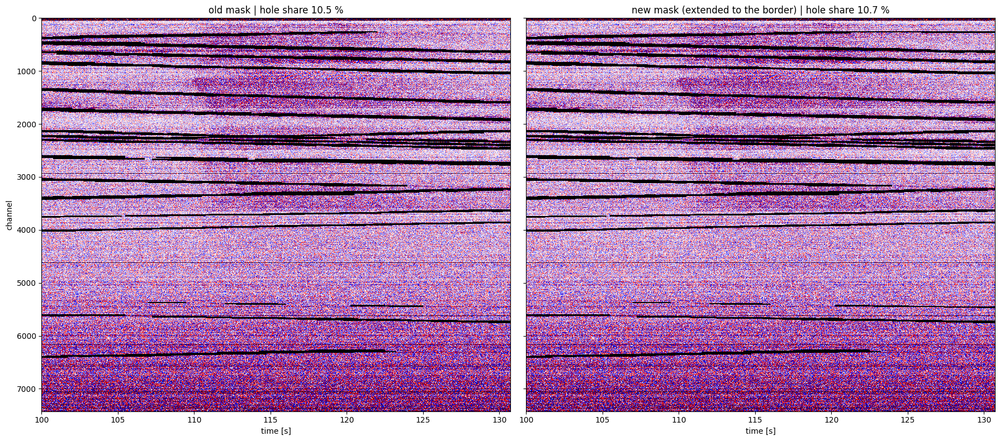

In [ ]:
ext_max_s = 10      # extend a line if it ends at most 10 s before the border (30 = always to the border)
max_resid = 6       # max. scatter around the fitted line [channels], otherwise it's not a straight line
max_slope = 5       # max. slope [channels per 0.25 s block] (~290 km/h)

# detections before widening (block resolution), slightly connected across channels so fragments join
core = (det*long)[0,0]
core_c = (F.max_pool2d(core[None,None], (5,3), 1, (2,1))[0,0] > 0).cpu().numpy()
Eb = E[0,0].cpu().numpy()

def label_np(b):
    """Connected components (8-neighborhood) without scipy."""
    lab = np.zeros(b.shape, np.int32); n = 0; Hb, Tb = b.shape
    for c_, t_ in zip(*np.nonzero(b)):
        if lab[c_, t_]: continue
        n += 1; lab[c_, t_] = n; stack = [(c_, t_)]
        while stack:
            c, t = stack.pop()
            for dc in (-1,0,1):
                for dt in (-1,0,1):
                    cn, tn = c+dc, t+dt
                    if 0 <= cn < Hb and 0 <= tn < Tb and b[cn,tn] and not lab[cn,tn]:
                        lab[cn,tn] = n; stack.append((cn,tn))
    return lab, n

lab, n = label_np(core_c)
cs_all, ts_all = np.nonzero(lab); ids = lab[cs_all, ts_all]
order = np.argsort(ids); cs_all, ts_all, ids = cs_all[order], ts_all[order], ids[order]
splits = np.flatnonzero(np.diff(ids)) + 1

ext_band = torch.zeros(H, W, dtype=torch.bool, device=device)
cc_full = torch.arange(H, device=device)[:,None].float()
n_ext = 0
for cs_i, ts_i in zip(np.split(cs_all, splits), np.split(ts_all, splits)):
    if (ts_i.max()-ts_i.min())*blk/fs < min_len_s: continue  # too short -> no traffic line
    a, b = np.polyfit(ts_i, cs_i, 1, w=np.sqrt(Eb[cs_i, ts_i]))
    if np.std(cs_i - (a*ts_i+b)) > max_resid or abs(a) > max_slope: continue
    for g0, g1 in [(0, ts_i.min()), (ts_i.max(), T_blk-1)]:   # gap left / right of the piece
        if g1 - g0 <= 0 or (g1-g0)*blk/fs > ext_max_s: continue
        s0 = 0 if g0 == 0 else int(g0*blk)
        s1 = W if g1 == T_blk-1 else int((g1+1)*blk)
        tt = torch.arange(s0, s1, device=device).float()
        c_line = a*((tt - blk/2)/blk) + b   # line in sample coordinates
        ext_band[:, s0:s1] |= (torch.abs(cc_full - c_line[None,:]) <= hw)
        n_ext += 1

M_old = M_full.clone()
M_full = M_old * (1.0 - ext_band.float().cpu())[None,None]
print(f"{n} components | {n_ext} line extensions | hole share {(M_old==0).float().mean()*100:.1f} % -> {(M_full==0).float().mean()*100:.1f} %")

# check: old vs. new mask
fig, ax = plt.subplots(1,2, figsize=(18,8), sharey=True)
for a_,(mm,t) in zip(ax, [(M_old,"old mask"), (M_full,"new mask (extended to the border)")]):
    xm = x_full[0,0].clone(); xm[mm[0,0]==0] = float("nan")
    a_.imshow(xm[::4,::2], aspect="auto", cmap=cmap, vmin=-w_full, vmax=w_full, interpolation="nearest", extent=ext)
    a_.set_title(f"{t} | hole share {(mm==0).float().mean()*100:.1f} %"); a_.set_xlabel("time [s]")
ax[0].set_ylabel("channel"); plt.tight_layout(); plt.show()
masked = x_full[0,0].clone(); masked[M_full[0,0]==0] = float("nan")

In [ ]:
def inpaint_strips(model, scale, x, m, strip=1024, overlap=128, seed=0, max_strips=None):
    """Fills the sample in strips of `strip` channels x the full time, each strip in one pass.
    Neighboring strips overlap; only the inner part of each strip is kept (no seams)."""
    H_, W_ = x.shape[-2:]
    starts = list(range(0, H_-strip, strip-overlap)) + [H_-strip]  # last strip ends at the border
    if max_strips: starts = starts[:max_strips]
    out = x.clone()
    gen = torch.Generator(device=device).manual_seed(seed)
    for k, s0 in enumerate(starts):
        xs, ms = x[..., s0:s0+strip, :].to(device), m[..., s0:s0+strip, :].to(device)
        if (ms == 0).any():
            r,_,_ = inpaint_scaled(model, scheduler_rad, xs, ms, device, scale=scale, generator=gen)
            r = r.cpu()
            lo = 0 if k == 0 else overlap//2    # skip the overlap edges, except at the image border
            hi = strip if s0 + strip == H_ else strip - overlap//2
            out[..., s0+lo:s0+hi, :] = r[..., lo:hi, :]
        torch.cuda.empty_cache()
        print(f"strip {k+1}/{len(starts)} (channels {s0}-{s0+strip}) done")
    return out

In [15]:
t0 = time.time()
_ = inpaint_strips(model_v2, 1.0, x_full, M_full, max_strips=1)
dt = time.time() - t0
n_strips = len(range(0, H-1024, 1024-128)) + 1
print(f"1 strip: {dt:.0f} s -> {n_strips} strips ≈ {dt*n_strips/60:.0f} min per model")

strip 1/1 (channels 0-1024) done
1 strip: 298 s -> 9 strips ≈ 45 min per model
